# 05 · Feed-forward Neural Network (PyTorch, trained by us)

Implementation: `src/neural_net.py`. Baseline network = the architecture suggested in the
project description: **input → 256 → 64 → output** (50 outputs for images, 3 for sentiment),
ReLU, Adam (lr = 0.001), batch size 128, 60 epochs, no regularisation.

Method: change **one hyperparameter at a time** from the baseline, measure validation accuracy,
then combine the helpful changes. After every epoch we record training and validation
loss/accuracy; we report the best validation accuracy and the epoch it occurred at, and
keep those weights (**early stopping**). The baseline runs train for all 60 epochs to show
overfitting; the sweeps stop once validation accuracy has not improved for 15 epochs
(`patience=15`), which saves a lot of time and rarely changes the best result.

In [1]:
import sys
import ast
import json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from src.common import *
from src.plotting import *
from src.neural_net import train_mlp, predict_proba
set_seed()
# These networks are small: one CPU thread is fastest (extra threads mostly add
# synchronisation overhead, and badly slow things down if another program is busy).
torch.set_num_threads(1)
print("PyTorch", torch.__version__, "| CPU threads:", torch.get_num_threads())

BASE = dict(hidden=(256, 64), activation="relu", dropout=0.0, lr=1e-3, optimizer="adam",
            weight_decay=0.0, batch_size=128, epochs=60)
splits = {t: get_split(t) for t in ("image", "sentiment")}
_cache = {}

def prepared(task, prep):
    """Preprocess train/val for a task (fitted on the training split only); cached."""
    if (task, prep) not in _cache:
        Xtr, ytr, Xva, yva = splits[task]
        pp = Preprocessor(prep).fit(Xtr)
        _cache[(task, prep)] = (pp.transform(Xtr), ytr, pp.transform(Xva), yva)
    return _cache[(task, prep)]

def run(task, prep, seed=SEED, patience=15, **overrides):
    cfg = {**BASE, **overrides}
    A, ytr, B, yva = prepared(task, prep)
    with Timer() as t:
        model, hist, best_epoch = train_mlp(A, ytr, B, yva, n_classes=N_CLASSES[task], seed=seed,
                                            patience=patience, **cfg)
    best = hist.loc[hist.val_acc.idxmax()]
    last = hist.iloc[-1]
    row = dict(task=task, preprocessing=prep, **{k: (str(v) if k == "hidden" else v) for k, v in cfg.items()},
               seed=seed, best_val_acc=best.val_acc, best_epoch=int(best.epoch),
               train_acc_at_best=best.train_acc, last_val_acc=last.val_acc, last_train_acc=last.train_acc,
               fit_s=round(t.seconds, 1))
    return row, hist, model

PyTorch 2.15.0+cu132 | CPU threads: 1


## 1 · Which preprocessing? (baseline network)

In [2]:
PREPS = {"image": ["none", "standardize", "hellinger", "hellinger+standardize"],
         "sentiment": ["none", "standardize"]}
rows, base_hist = [], {}
for task in splits:
    for prep in PREPS[task]:
        row, hist, _ = run(task, prep, patience=None)          # full 60 epochs
        rows.append(row); base_hist[(task, prep)] = hist
        print(f"{task:9s} {prep:22s} best val {row['best_val_acc']:.4f} @ epoch {row['best_epoch']:2d} | "
              f"last epoch: train {row['last_train_acc']:.3f}, val {row['last_val_acc']:.4f}  ({row['fit_s']}s)")
prep_results = pd.DataFrame(rows)
save_table(prep_results, "nn_preprocessing")
PREP = {t: prep_results[prep_results.task == t].sort_values("best_val_acc").iloc[-1].preprocessing for t in splits}
print("chosen preprocessing:", PREP)

image     none                   best val 0.3155 @ epoch 45 | last epoch: train 0.965, val 0.3142  (26.6s)


image     standardize            best val 0.3335 @ epoch  6 | last epoch: train 1.000, val 0.3270  (24.2s)


image     hellinger              best val 0.3003 @ epoch 45 | last epoch: train 0.981, val 0.2925  (25.0s)


image     hellinger+standardize  best val 0.3270 @ epoch  8 | last epoch: train 1.000, val 0.3222  (23.6s)


sentiment none                   best val 0.6783 @ epoch  3 | last epoch: train 1.000, val 0.6242  (19.8s)


sentiment standardize            best val 0.6725 @ epoch  1 | last epoch: train 1.000, val 0.6312  (17.2s)
chosen preprocessing: {'image': 'standardize', 'sentiment': 'none'}


Standardising helps the network a little on images (33.4% vs 31.6% raw). The Hellinger transform,
which helped k-NN, does *not* help the network (30.0%): a network can learn its own rescaling of
each feature, whereas k-NN's distances depend directly on the scale. For sentiment, raw and standardised
inputs are equivalent (67.8% vs 67.3%).

## 2 · Learning curves of the baseline network
Training accuracy keeps rising while validation loss turns upward. That turn is where the
network stops learning general patterns and starts memorising the training set.

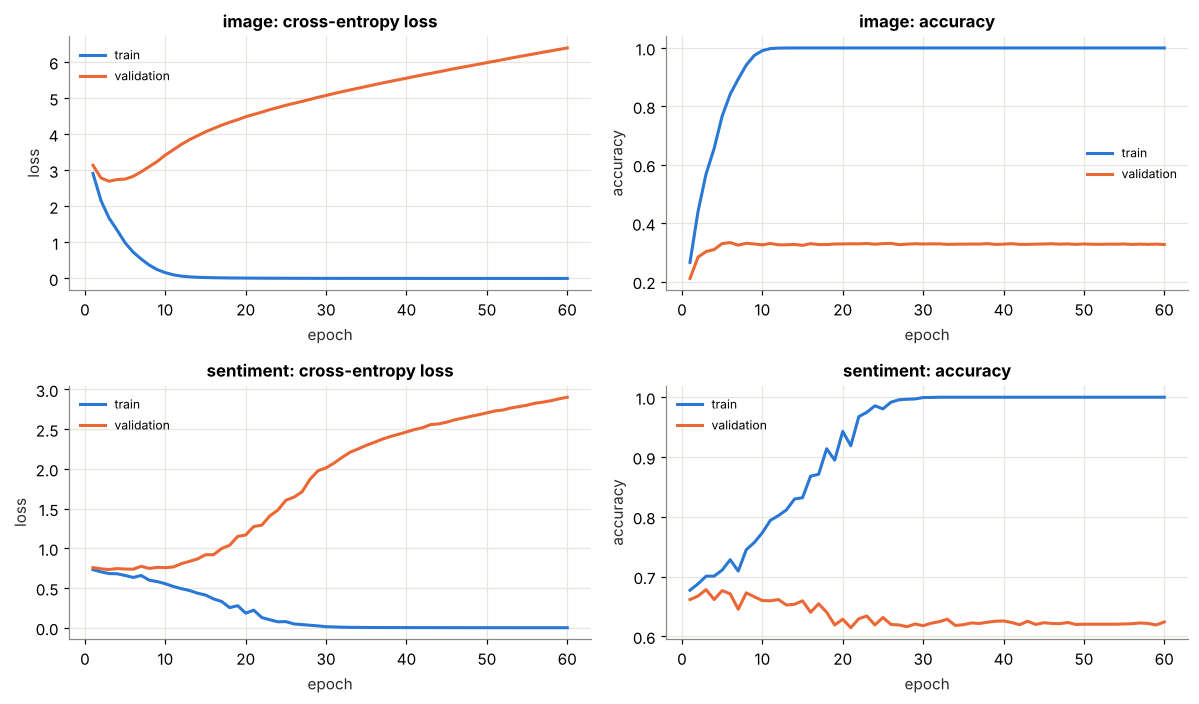

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for i, task in enumerate(("image", "sentiment")):
    h = base_hist[(task, PREP[task])]
    axes[i, 0].plot(h.epoch, h.train_loss, color=PALETTE[0], label="train")
    axes[i, 0].plot(h.epoch, h.val_loss, color=PALETTE[1], label="validation")
    axes[i, 0].set_title(f"{task}: cross-entropy loss"); axes[i, 0].set_xlabel("epoch"); axes[i, 0].set_ylabel("loss")
    axes[i, 1].plot(h.epoch, h.train_acc, color=PALETTE[0], label="train")
    axes[i, 1].plot(h.epoch, h.val_acc, color=PALETTE[1], label="validation")
    axes[i, 1].set_title(f"{task}: accuracy"); axes[i, 1].set_xlabel("epoch"); axes[i, 1].set_ylabel("accuracy")
    for ax in axes[i]:
        ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "05_nn_baseline_curves"); plt.show()

## 3 · One hyperparameter at a time
`last_*` columns = the epoch where training stopped (15 epochs after the best one, or epoch 60).

In [4]:
SWEEPS = {
    "lr": [dict(lr=1e-2), dict(lr=1e-3), dict(lr=1e-4)],
    "hidden": [dict(hidden=()), dict(hidden=(64,)), dict(hidden=(256,)), dict(hidden=(256, 64)),
               dict(hidden=(512, 256)), dict(hidden=(1024, 512))],
    "activation": [dict(activation=a) for a in ("relu", "gelu", "tanh", "sigmoid")],
    "dropout": [dict(dropout=p) for p in (0.0, 0.2, 0.5)],
    "weight_decay": [dict(weight_decay=w) for w in (0.0, 1e-5, 1e-4, 1e-3)],
    "batch_size": [dict(batch_size=b) for b in (32, 128, 512)],
    "optimizer": [dict(optimizer="adam", lr=1e-3), dict(optimizer="sgd", lr=1e-2)],
}
rows = []
for task in splits:
    for name, variants in SWEEPS.items():
        for ov in variants:
            row, _, _ = run(task, PREP[task], **ov)
            row["sweep"] = name
            row["setting"] = ", ".join(f"{k}={v}" for k, v in ov.items())
            rows.append(row)
        print(task, name, "done")
sweep_results = pd.DataFrame(rows)
save_table(sweep_results, "nn_sweeps")
cols = ["sweep", "setting", "best_val_acc", "best_epoch", "last_val_acc", "last_train_acc", "fit_s"]
for task in splits:
    print(f"\n=== {task} ===")
    print(sweep_results[sweep_results.task == task][cols].round(4).to_string(index=False))

image lr done


image hidden done


image activation done


image dropout done


image weight_decay done


image batch_size done


... (4 outputs left out)

sentiment dropout done


sentiment weight_decay done


sentiment batch_size done


sentiment optimizer done

=== image ===
       sweep                  setting  best_val_acc  best_epoch  last_val_acc  last_train_acc  fit_s
          lr                  lr=0.01        0.2120          19        0.2035          0.6241   14.4
          lr                 lr=0.001        0.3335           6        0.3295          1.0000    8.4
          lr                lr=0.0001        0.3295          57        0.3292          0.9238   23.5
      hidden                hidden=()        0.3147           7        0.2935          0.6011    4.6
      hidden             hidden=(64,)        0.3030           7        0.2735          0.7756    4.7
      hidden            hidden=(256,)        0.3468           5        0.3450          1.0000    7.6
      hidden         hidden=(256, 64)        0.3335           6        0.3295          1.0000    8.3
      hidden        hidden=(512, 256)        0.3680          42        0.3662          1.0000   45.0
      hidden       hidden=(1024, 512)        0.3915

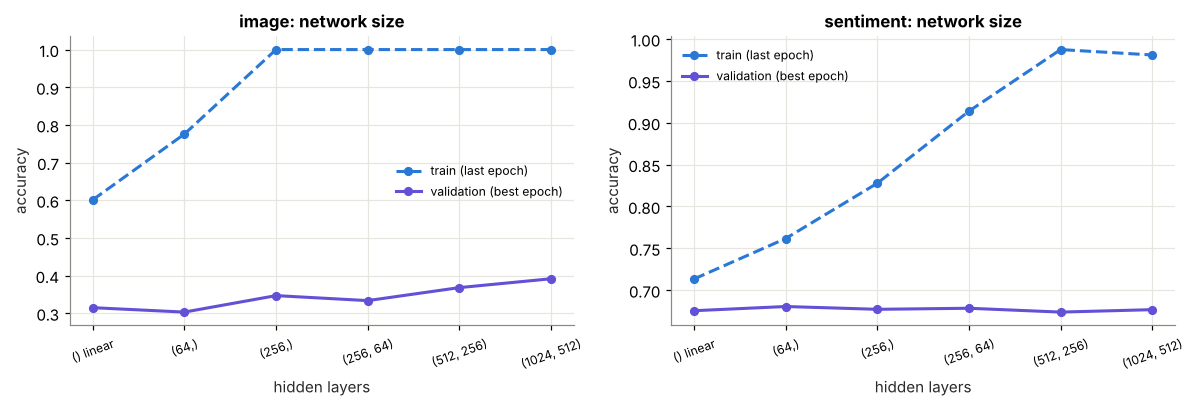

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    r = sweep_results[(sweep_results.task == task) & (sweep_results.sweep == "hidden")]
    labels = [s.replace("hidden=", "") for s in r.setting]
    labels = ["() linear" if l == "()" else l for l in labels]
    x = np.arange(len(r))
    ax.plot(x, r.last_train_acc, color=PALETTE[0], linestyle="--", marker="o", label="train (last epoch)")
    ax.plot(x, r.best_val_acc, color=PALETTE[6], marker="o", label="validation (best epoch)")
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20, fontsize=8)
    ax.set_xlabel("hidden layers"); ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: network size")
    ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "05_nn_hidden_size"); plt.show()

**What the sweeps show**
* **Learning rate:** 0.01 is too large on images (21%: updates overshoot); 0.0001 reaches the same
  accuracy as 0.001 but needs ~10× more epochs.
* **Size:** on images, wider networks help (linear 31.5%, 256-64 33.4%, 1024-512 39.1%); on sentiment,
  *every* size, including a network with no hidden layer (= logistic regression, 67.5%), lands at
  67.4–68.0%. Extra capacity only adds overfitting (training accuracy goes up, validation doesn't).
* **Activation:** ReLU/GELU beat tanh/sigmoid on images (33–34% vs 28–29%); no difference on sentiment.
* **Dropout / weight decay:** dropout hurts on images (fewer effective units for 50 classes) but on
  sentiment it slows overfitting (last-epoch accuracy 67.4% with dropout 0.5 vs 64.0% without), even if
  the best epoch is no better. Weight decay 1e-3 gives a small gain on images.
* **Batch size / optimiser:** small effects (about 1% or less). Small batches = more updates per epoch but slower
  epochs. SGD with momentum ends slightly below Adam.

Every sentiment variation is within ~1% of the others, i.e. within validation noise (±1%). The sentiment
features seem to contain about 68% worth of linearly usable sentiment information, and no network
extracts more.

## 4 · Combining the helpful settings
A small grid over capacity and regularisation, which the one-at-a-time sweeps suggest matter most.

In [6]:
GRID = [dict(hidden=h, dropout=p, weight_decay=w)
        for h in ((512, 256), (1024, 512)) for p in (0.3, 0.5) for w in (0.0, 1e-4)]
rows = []
for task in splits:
    for ov in GRID:
        row, _, _ = run(task, PREP[task], epochs=80, **ov)
        row["setting"] = ", ".join(f"{k}={v}" for k, v in ov.items())
        rows.append(row)
        print(f"{task:9s} {row['setting']:55s} best val {row['best_val_acc']:.4f} @ {row['best_epoch']}")
grid_results = pd.DataFrame(rows)
save_table(grid_results, "nn_grid")

image     hidden=(512, 256), dropout=0.3, weight_decay=0.0        best val 0.3698 @ 10


image     hidden=(512, 256), dropout=0.3, weight_decay=0.0001     best val 0.3743 @ 33


image     hidden=(512, 256), dropout=0.5, weight_decay=0.0        best val 0.3568 @ 26


image     hidden=(512, 256), dropout=0.5, weight_decay=0.0001     best val 0.3695 @ 36


image     hidden=(1024, 512), dropout=0.3, weight_decay=0.0       best val 0.3830 @ 30


image     hidden=(1024, 512), dropout=0.3, weight_decay=0.0001    best val 0.3840 @ 14


... (7 outputs left out)

sentiment hidden=(1024, 512), dropout=0.3, weight_decay=0.0001    best val 0.6775 @ 5


sentiment hidden=(1024, 512), dropout=0.5, weight_decay=0.0       best val 0.6792 @ 6


sentiment hidden=(1024, 512), dropout=0.5, weight_decay=0.0001    best val 0.6796 @ 16


PosixPath('/home/claude/COMP472-Project/results/tables/nn_grid.csv')

None of the combinations beats the best single change on images ((1024, 512), no dropout: 39.1%);
on sentiment the best cell (512-256, dropout 0.5: 68.3%) is within noise of everything else.

## 5 · Final network: robustness to the random seed, and a 5-seed ensemble
Different seeds give different initial weights and batch orders. Averaging the predicted
probabilities of several networks (an ensemble) usually gives a small, reliable gain.

In [7]:
TUNED, final_rows, final_info = {}, [], {}
for task in splits:
    g = grid_results[grid_results.task == task].sort_values("best_val_acc").iloc[-1]
    b = sweep_results[sweep_results.task == task].sort_values("best_val_acc").iloc[-1]
    # take whichever was better: the best grid cell or the best single-change setting
    src = g if g.best_val_acc >= b.best_val_acc else b
    TUNED[task] = dict(hidden=tuple(ast.literal_eval(src.hidden)),
                       activation=src.activation, dropout=float(src.dropout), lr=float(src.lr),
                       optimizer=src.optimizer, weight_decay=float(src.weight_decay),
                       batch_size=int(src.batch_size), epochs=int(src.epochs))
    print(task, "tuned config:", TUNED[task])

    probas, epochs_seen, seed_accs = [], [], []
    A, ytr, B, yva = prepared(task, PREP[task])
    for seed in range(5):
        with Timer() as t:
            model, hist, best_epoch = train_mlp(A, ytr, B, yva, n_classes=N_CLASSES[task], seed=SEED + seed,
                                                patience=15, **TUNED[task])
        with Timer() as tp:
            p = predict_proba(model, B)
        probas.append(p); epochs_seen.append(best_epoch); seed_accs.append(accuracy(yva, p.argmax(1)))
        if seed == 0:
            single = dict(pred=p.argmax(1), proba=p, fit_s=t.seconds, pred_s=tp.seconds,
                          train_acc=hist.loc[hist.epoch == best_epoch, "train_acc"].item(), hist=hist)
    ens = np.mean(probas, axis=0)
    final_rows.append(dict(task=task, seeds_mean_acc=np.mean(seed_accs), seeds_std_acc=np.std(seed_accs),
                           seeds_min=np.min(seed_accs), seeds_max=np.max(seed_accs),
                           ensemble5_acc=accuracy(yva, ens.argmax(1)), best_epochs=epochs_seen))
    info = dict(model="Neural Network", config={**TUNED[task], "hidden": list(TUNED[task]["hidden"])},
                preprocessing=PREP[task], val_acc=seed_accs[0], train_acc=single["train_acc"],
                best_epoch=int(epochs_seen[0]), best_epochs_5_seeds=[int(e) for e in epochs_seen],
                seeds_mean_acc=float(np.mean(seed_accs)), ensemble5_val_acc=accuracy(yva, ens.argmax(1)),
                fit_seconds=single["fit_s"], predict_seconds=single["pred_s"])
    save_val_predictions(task, "nn", single["pred"], single["proba"], info)
    np.save(PRED_DIR / f"{task}_nn_ensemble5_proba.npy", ens)
    single["hist"].to_csv(TABLES_DIR / f"nn_tuned_history_{task}.csv", index=False)
    final_info[task] = info
pd.DataFrame(final_rows).round(4)

image tuned config: {'hidden': (1024, 512), 'activation': 'relu', 'dropout': 0.0, 'lr': 0.001, 'optimizer': 'adam', 'weight_decay': 0.0, 'batch_size': 128, 'epochs': 60}


sentiment tuned config: {'hidden': (512, 256), 'activation': 'relu', 'dropout': 0.5, 'lr': 0.001, 'optimizer': 'adam', 'weight_decay': 0.0, 'batch_size': 128, 'epochs': 80}


,task,seeds_mean_acc,seeds_std_acc,seeds_min,seeds_max,ensemble5_acc,best_epochs
0,image,0.3882,0.0064,0.3762,0.3950,0.4095,"[29, 33, 24, 23, 8]"
1,sentiment,0.6795,0.0030,0.6754,0.6829,0.6800,"[16, 9, 4, 5, 9]"


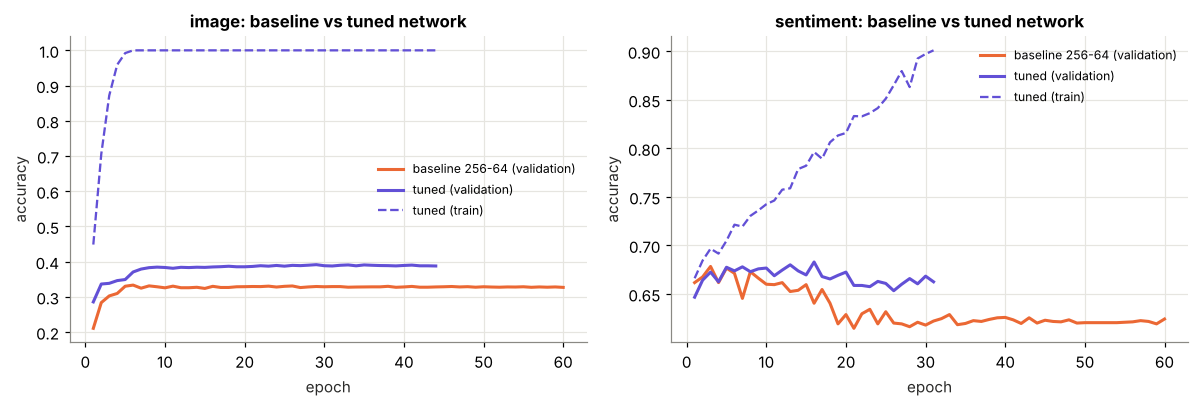

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, ("image", "sentiment")):
    h = pd.read_csv(TABLES_DIR / f"nn_tuned_history_{task}.csv")
    hb = base_hist[(task, PREP[task])]
    ax.plot(hb.epoch, hb.val_acc, color=PALETTE[1], label="baseline 256-64 (validation)")
    ax.plot(h.epoch, h.val_acc, color=PALETTE[6], label="tuned (validation)")
    ax.plot(h.epoch, h.train_acc, color=PALETTE[6], linestyle="--", linewidth=1.5, label="tuned (train)")
    ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_title(f"{task}: baseline vs tuned network")
    ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "05_nn_tuned_vs_baseline"); plt.show()

**Final networks.** Images: 38.8% ± 0.6% across 5 seeds; averaging the 5 networks gives 41.0%
(ensembles help most when individual models are unstable). Sentiment: 68.0% ± 0.3%; the ensemble
gives the same 68.0%.

**Why is the network so much weaker than k-NN on images (≈ 39% vs ≈ 58%)?** The network memorises
the training set within ~10 epochs (100% training accuracy) but must squeeze each class into one
smooth decision function. Notebook 02 showed image classes are made of many small groups of
near-relatives. Recognising "this is a close relative of training image #8,123" is exactly what k-NN
does and what a parametric model does poorly with only 320 examples per class.